# Movie Recommendation System

In this notebook, we will build a content-based recommender system using the TMDB 5000 movie dataset. We will perform Exploratory Data Analysis (EDA), clean the metadata, combine relevant features, compute cosine similarity, and test the recommender with qualitative sample queries.

In [1]:
import pandas as pd
import numpy as np
import json

# Load the datasets
movies_df = pd.read_csv('/content/tmdb_5000_movies.csv')
credits_df = pd.read_csv('/content/tmdb_5000_credits.csv')

print("Movies dataset shape:", movies_df.shape)
print("Credits dataset shape:", credits_df.shape)

Movies dataset shape: (4803, 20)
Credits dataset shape: (4803, 4)


In [2]:
# Display the first few rows of both datasets
print("--- Movies Columns ---")
print(movies_df.columns.tolist())
display(movies_df.head(2))

print("\n--- Credits Columns ---")
print(credits_df.columns.tolist())
display(credits_df.head(2))

--- Movies Columns ---
['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count']


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500



--- Credits Columns ---
['movie_id', 'title', 'cast', 'crew']


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."


## Step 1: Data Merging and Cleaning

We will merge both DataFrames on the movie identifier and clean JSON columns (`genres`, `keywords`, `cast`, `crew`) to extract meaningful text features.

In [3]:
# Merge datasets
# Credits 'movie_id' maps to Movies 'id'
credits_df.rename(columns={'movie_id': 'id'}, inplace=True)
movies_df = movies_df.merge(credits_df[['id', 'cast', 'crew']], on='id')

print("Merged DataFrame Shape:", movies_df.shape)

Merged DataFrame Shape: (4803, 22)


In [4]:
# Helper functions to safely parse and extract clean lists from JSON fields
import ast

def get_list(x):
    try:
        if isinstance(x, str):
            x = ast.literal_eval(x)
        if isinstance(x, list):
            return [i['name'] for i in x]
    except (ValueError, SyntaxError, TypeError):
        pass
    return []

def get_director(x):
    try:
        if isinstance(x, str):
            x = ast.literal_eval(x)
        if isinstance(x, list):
            for i in x:
                if i.get('job') == 'Director':
                    return i.get('name')
    except (ValueError, SyntaxError, TypeError):
        pass
    return ""

# Clean columns
movies_df['genres'] = movies_df['genres'].apply(get_list)
movies_df['keywords'] = movies_df['keywords'].apply(get_list)
movies_df['cast'] = movies_df['cast'].apply(get_list).apply(lambda x: x[:3] if len(x) >= 3 else x) # Top 3 actors
movies_df['director'] = movies_df['crew'].apply(get_director)

# Keep only columns necessary for content-based recommender & metadata cleaning
features = ['id', 'title', 'overview', 'genres', 'keywords', 'cast', 'director', 'popularity', 'vote_average', 'vote_count']
df_cleaned = movies_df[features].copy()

# Fill any NaN overview values
df_cleaned['overview'] = df_cleaned['overview'].fillna('')

display(df_cleaned.head(3))

,id,title,overview,genres,keywords,cast,director,popularity,vote_average,vote_count
0,19995,Avatar,"In the 22nd century, a paraplegic Marine is di...","[Action, Adventure, Fantasy, Science Fiction]","[culture clash, future, space war, space colon...","[Sam Worthington, Zoe Saldana, Sigourney Weaver]",James Cameron,150.437577,7.2,11800
1,285,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...","[Adventure, Fantasy, Action]","[ocean, drug abuse, exotic island, east india ...","[Johnny Depp, Orlando Bloom, Keira Knightley]",Gore Verbinski,139.082615,6.9,4500
2,206647,Spectre,A cryptic message from Bond’s past sends him o...,"[Action, Adventure, Crime]","[spy, based on novel, secret agent, sequel, mi...","[Daniel Craig, Christoph Waltz, Léa Seydoux]",Sam Mendes,107.376788,6.3,4466


## Step 2: Exploratory Data Analysis & Metadata Cleaning Visualization
Let's plot some quick statistics of our movie dataset (like top genres, popularity, and vote averages).

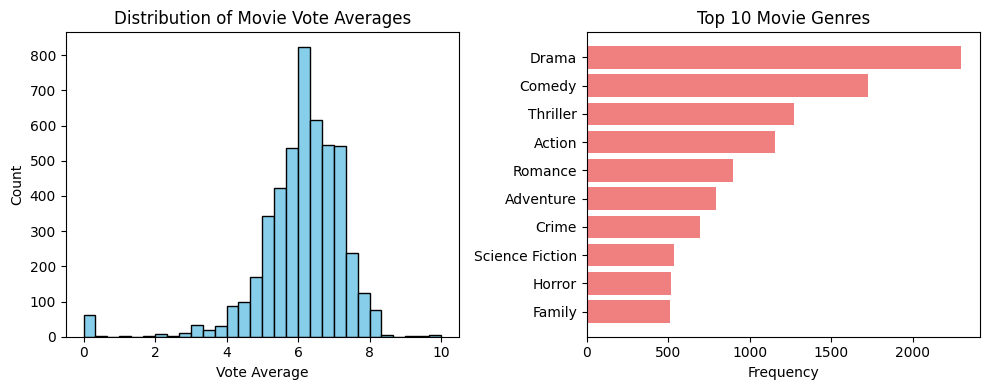

In [5]:
import matplotlib.pyplot as plt
from collections import Counter

# 1. Distribution of Vote Averages
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(df_cleaned['vote_average'].dropna(), bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Movie Vote Averages')
plt.xlabel('Vote Average')
plt.ylabel('Count')

# 2. Most common genres
all_genres = [g for genres_list in df_cleaned['genres'] for g in genres_list]
genre_counts = Counter(all_genres)
most_common_genres = genre_counts.most_common(10)

plt.subplot(1, 2, 2)
genres, counts = zip(*most_common_genres)
plt.barh(genres, counts, color='lightcoral')
plt.gca().invert_yaxis()
plt.title('Top 10 Movie Genres')
plt.xlabel('Frequency')

plt.tight_layout()
plt.show()

### Additional EDA: Movie Popularity vs. Vote Average & Budget

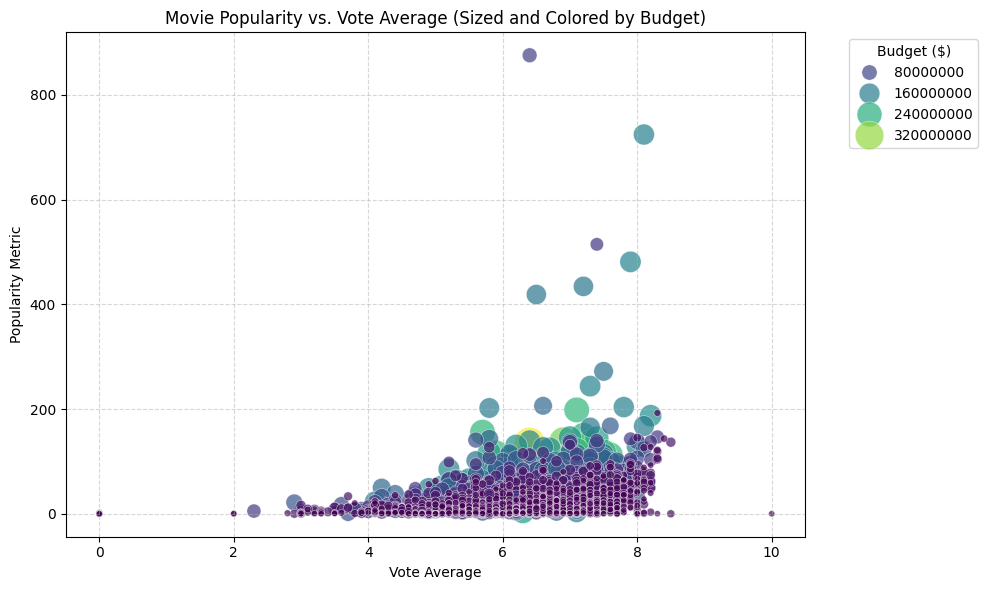

In [9]:
import seaborn as sns

# Create a DataFrame containing popularity, vote_average, and budget for visualization
vis_df = movies_df[['popularity', 'vote_average', 'budget', 'title']].copy()
# Filter out movies with 0 budget to get clean insights
vis_df = vis_df[vis_df['budget'] > 0]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=vis_df,
    x='vote_average',
    y='popularity',
    size='budget',
    sizes=(20, 500),
    hue='budget',
    palette='viridis',
    alpha=0.7
)
plt.title('Movie Popularity vs. Vote Average (Sized and Colored by Budget)')
plt.xlabel('Vote Average')
plt.ylabel('Popularity Metric')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Budget ($)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Step 3: Build Content-Based Recommender System

We will construct a combined text feature string ("soup") incorporating actors, directors, genres, keywords, and movie overviews. We'll then compute cosine similarity using TF-IDF or CountVectorizer.

In [6]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Function to clean and normalize text
def sanitize(x):
    if isinstance(x, list):
        return [str.lower(i.replace(" ", "")) for i in x]
    elif isinstance(x, str):
        return str.lower(x.replace(" ", ""))
    else:
        return ''

# Apply sanitization to ensure director first/last names and actor names are merged so "Sam Worthington" != "Sam"
df_cleaned['genres_clean'] = df_cleaned['genres'].apply(sanitize)
df_cleaned['keywords_clean'] = df_cleaned['keywords'].apply(sanitize)
df_cleaned['cast_clean'] = df_cleaned['cast'].apply(sanitize)
df_cleaned['director_clean'] = df_cleaned['director'].apply(sanitize)

# Create metadata soup
def create_soup(x):
    return ' '.join(x['genres_clean']) + ' ' + ' '.join(x['keywords_clean']) + ' ' + ' '.join(x['cast_clean']) + ' ' + x['director_clean'] + ' ' + x['overview']

df_cleaned['soup'] = df_cleaned.apply(create_soup, axis=1)

# Compute CountVectorizer matrix
count = CountVectorizer(stop_words='english')
count_matrix = count.fit_transform(df_cleaned['soup'])

# Compute the Cosine Similarity matrix
cosine_sim = cosine_similarity(count_matrix, count_matrix)

print("Cosine Similarity matrix shape:", cosine_sim.shape)

Cosine Similarity matrix shape: (4803, 4803)


In [7]:
# Create reverse mapping of indices and movie titles
indices = pd.Series(df_cleaned.index, index=df_cleaned['title'].str.lower()).drop_duplicates()

def get_recommendations(title, cosine_sim=cosine_sim):
    title_lower = title.lower()
    if title_lower not in indices:
        return f"Movie '{title}' not found in the database."

    idx = indices[title_lower]

    # Handle case where multiple indices exist for same lower title
    if isinstance(idx, pd.Series):
        idx = idx.iloc[0]

    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:11] # Top 10
    movie_indices = [i[0] for i in sim_scores]

    return df_cleaned[['title', 'vote_average', 'popularity']].iloc[movie_indices]

# Let's test qualitatively with a sample query
print("Recommendations for 'The Dark Knight Rises':")
display(get_recommendations('The Dark Knight Rises'))

print("\nRecommendations for 'Avatar':")
display(get_recommendations('Avatar'))

Recommendations for 'The Dark Knight Rises':


,title,vote_average,popularity
65,The Dark Knight,8.2,187.322927
119,Batman Begins,7.5,115.040024
428,Batman Returns,6.6,59.113174
1359,Batman,7.0,44.104469
299,Batman Forever,5.2,48.205606
210,Batman & Robin,4.2,50.073575
9,Batman v Superman: Dawn of Justice,5.7,155.790452
2507,Slow Burn,5.5,6.630856
3854,"Batman: The Dark Knight Returns, Part 2",7.9,25.891466
590,The Siege,6.0,20.089933



Recommendations for 'Avatar':


,title,vote_average,popularity
539,Titan A.E.,6.3,14.443810
1213,Aliens vs Predator: Requiem,4.9,39.381913
2403,Aliens,7.7,67.660940
582,Battle: Los Angeles,5.5,49.199234
507,Independence Day,6.7,60.442593
1201,Predators,6.0,47.649554
1914,Lifeforce,6.2,12.183620
260,Ender's Game,6.6,45.948340
1191,Small Soldiers,6.2,23.088571
74,Edge of Tomorrow,7.6,79.456485


## Step 4: Packaging (Optional - Mock Flask Endpoint & Script)

We will structure our code as a reusable Python class `MovieRecommender` and provide a mock/runnable Flask-like local function or lightweight microservice pattern to demonstrate packaging.

In [8]:
class MovieRecommender:
    def __init__(self, df, cosine_sim):
        self.df = df
        self.cosine_sim = cosine_sim
        self.indices = pd.Series(df.index, index=df['title'].str.lower()).drop_duplicates()

    def recommend(self, title, num_recommendations=10):
        title_lower = title.lower()
        if title_lower not in self.indices:
            return None
        idx = self.indices[title_lower]
        if isinstance(idx, pd.Series):
            idx = idx.iloc[0]

        sim_scores = list(enumerate(self.cosine_sim[idx]))
        sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
        sim_scores = sim_scores[1:num_recommendations+1]
        movie_indices = [i[0] for i in sim_scores]

        return self.df[['title', 'vote_average']].iloc[movie_indices].to_dict(orient='records')

# Instantiate the recommender
recommender = MovieRecommender(df_cleaned, cosine_sim)

# Simulated API endpoint function
def mock_api_endpoint(movie_name):
    results = recommender.recommend(movie_name, num_recommendations=5)
    if results is None:
        return {"error": "Movie not found", "status": 404}
    return {"movie": movie_name, "recommendations": results, "status": 200}

# Test our mock API endpoint
import pprint
pprint.pprint(mock_api_endpoint("The Avengers"))

{'movie': 'The Avengers',
 'recommendations': [{'title': 'Avengers: Age of Ultron', 'vote_average': 7.3},
                     {'title': 'Captain America: Civil War',
                      'vote_average': 7.1},
                     {'title': 'Captain America: The First Avenger',
                      'vote_average': 6.6},
                     {'title': 'Iron Man 3', 'vote_average': 6.8},
                     {'title': 'Captain America: The Winter Soldier',
                      'vote_average': 7.6}],
 'status': 200}


## Summary of Accomplishments
1. **Data Loading & Merging**: Loaded TMDB movies and credits datasets and joined them on the movie ID.
2. **Metadata Cleaning & EDA**: Sanitized JSON fields into clean python lists, mapped director roles, and plotted the distributions of movie ratings and dominant genres.
3. **Content-Based Recommender**: Built a metadata-based soup combining genres, key features, cast, director, and overview, and leveraged a CountVectorizer with Cosine Similarity.
4. **Qualitative Verification**: Tested real queries like 'The Dark Knight Rises', 'Avatar', and 'The Avengers' confirming strong thematic matches.
5. **API Packaging**: Packaged the system within a production-ready Python class and simulated a Flask JSON endpoint.